In [1]:
!pip install easyfsl


In [2]:
!pip -q install gdown

import tarfile
import subprocess
from pathlib import Path

DRIVE_FOLDER = "https://drive.google.com/drive/folders/17a09kkqVivZQFggCw9I_YboJ23tcexNM"

DOWNLOAD_DIR = Path("/kaggle/working/miniimagenet_archives")
DATA_DIR = Path("/kaggle/working/miniimagenet")

DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Download the files in the shared Drive folder
result = subprocess.run([
    "gdown", "--folder", DRIVE_FOLDER,
    "-O", str(DOWNLOAD_DIR)
], check=False)

print("Download command exit code:", result.returncode)
print("Downloaded files:")
for p in DOWNLOAD_DIR.rglob("*"):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size / 1e6:.1f} MB")

# Find and extract train, val, and test archives
for split in ("train", "val", "test"):
    matches = list(DOWNLOAD_DIR.rglob(f"{split}.tar"))
    if not matches:
        raise FileNotFoundError(
            f"{split}.tar was not found. Check that the Drive folder "
            "is publicly accessible and the download completed."
        )

    archive = matches[0]
    out_dir = DATA_DIR / split
    out_dir.mkdir(parents=True, exist_ok=True)

    print(f"\nExtracting {archive.name} into {out_dir} ...")
    with tarfile.open(archive, "r:*") as tar:
        tar.extractall(out_dir, filter="data")

    print(f"Finished extracting {split}")

print("\nTop-level extracted structure:")
for split_dir in sorted(DATA_DIR.iterdir()):
    if split_dir.is_dir():
        print(split_dir.name, "->", [
            p.name for p in list(split_dir.iterdir())[:8]
        ])

Retrieving folder contents
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1yKyKgxcnGMIAnA_6Vr2ilbpHMc9COg-v
To: /kaggle/working/miniimagenet_archives/test.tar
 28%|██▊       | 11.0M/39.2M [00:00<00:00, 99.9MB/s]

Processing file 1yKyKgxcnGMIAnA_6Vr2ilbpHMc9COg-v test.tar
Processing file 107FTosYIeBn5QbynR46YG91nHcJ70whs train.tar
Processing file 1hSMUMj5IRpf-nQs1OwgiQLmGZCN0KDWl val.tar


100%|██████████| 39.2M/39.2M [00:00<00:00, 91.6MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=107FTosYIeBn5QbynR46YG91nHcJ70whs
From (redirected): https://drive.google.com/uc?id=107FTosYIeBn5QbynR46YG91nHcJ70whs&confirm=t&uuid=737e1a81-9df4-415a-a694-82bbfe471354
To: /kaggle/working/miniimagenet_archives/train.tar
100%|██████████| 126M/126M [00:00<00:00, 161MB/s]
Downloading...
From: https://drive.google.com/uc?id=1hSMUMj5IRpf-nQs1OwgiQLmGZCN0KDWl
To: /kaggle/working/miniimagenet_archives/val.tar
100%|██████████| 30.8M/30.8M [00:00<00:00, 86.8MB/s]
Download completed


Download command exit code: 0
Downloaded files:
val.tar: 30.8 MB
test.tar: 39.2 MB
train.tar: 125.9 MB

Extracting train.tar into /kaggle/working/miniimagenet/train ...
Finished extracting train

Extracting val.tar into /kaggle/working/miniimagenet/val ...
Finished extracting val

Extracting test.tar into /kaggle/working/miniimagenet/test ...
Finished extracting test

Top-level extracted structure:
test -> ['test']
train -> ['train']
val -> ['val']


In [3]:
# Environment and imports
# Run this notebook in Kaggle with the MiniImageNet class-folder dataset attached.
import os, time, random
from collections import defaultdict
import numpy as np
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Sampler
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models.feature_extraction import create_feature_extractor, get_graph_node_names
from easyfsl.samplers import TaskSampler
from tqdm.auto import tqdm
import multiprocessing

# Force 'spawn' start method to eliminate Python 3.13 multiprocessing cleanup warnings
try:
    multiprocessing.set_start_method('spawn', force=True)
except RuntimeError:
    pass

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

ROOT_DIRECTORY = "/kaggle/working/miniimagenet"
TRAIN_DIR = f"{ROOT_DIRECTORY}/train/train"
VAL_DIR   = f"{ROOT_DIRECTORY}/val/val"
TEST_DIR  = f"{ROOT_DIRECTORY}/test/test"

SAVE_PATH = '/kaggle/working/saved_models'
os.makedirs(SAVE_PATH, exist_ok=True)

# ---------------- Experiment configuration (single source of truth) ----------------
IMAGE_SIZE = 84
MAX_EPOCHS = 10
N_TRAINING_EPISODES = 360
N_VALIDATION_TASKS = 600
N_TEST_TASKS = 600
TRAIN_WAY = 30
TEST_WAY = 5
SHOT = 5
QUERY = 15

# Speedup: Process full support (150) and query (450) batches without tiny chunk loops
FEATURE_CHUNK_SIZE = 600
ATTENTION_CHUNK_SIZE = 600

# Novelty 1: Distance metric ('euclidean', 'cosine', or 'hybrid')
DISTANCE_METRIC = 'cosine'
COSINE_TEMP = 10.0           # Learnable temperature scaling for sharp CrossEntropy logits
USE_AMP = True               # Uses Tesla T4 Tensor Cores for 2x faster training

# Novelty 2: Task-Adaptive Dynamic Stage Weighting (Test-Time Task Adaptation)
DYNAMIC_STAGE_WEIGHTS = True
DYNAMIC_GATE_SCALE = 0.5     # Max modulation (+/- 50%) around global prior weights
FISHER_TEMP = 2.0            # Softmax temperature for support-set Fisher discriminability

# Multi-scale stages (ResNet-18 module names; the last node of each module is used).
STAGE_NODES   = ('maxpool', 'layer1', 'layer2', 'layer3', 'layer4')
STAGE_WEIGHTS = (1.0, 1.1, 1.2, 1.3, 1.4)

# NOTE: miniImageNet is a subset of ImageNet-1k, so ImageNet-pretrained weights have already
# seen the val/test classes. Set to False for a leakage-free few-shot benchmark.
USE_IMAGENET_PRETRAINED = True
NUM_WORKERS = 0   # Keep 0 to avoid IPC pickling overhead, or 2 with top-level Dataset wrapper

# ImageNet normalization matches the pretrained ResNet-18 weights.
_norm = transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    _norm,
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    _norm,
])
print('Imports and configuration ready.')

Device: cuda
GPU: Tesla T4
Imports and configuration ready.


In [4]:
from pathlib import Path

for split, path in [
    ("train", TRAIN_DIR),
    ("val", VAL_DIR),
    ("test", TEST_DIR),
]:
    p = Path(path)
    classes = [d for d in p.iterdir() if d.is_dir()] if p.exists() else []

    print(f"{split}: exists={p.exists()}, class folders={len(classes)}")
    print("Examples:", [d.name for d in classes[:5]])

train: exists=True, class folders=64
Examples: ['n03924679', 'n09246464', 'n03854065', 'n03476684', 'n04067472']
val: exists=True, class folders=16
Examples: ['n03535780', 'n03773504', 'n02981792', 'n02138441', 'n03980874']
test: exists=True, class folders=20
Examples: ['n02443484', 'n02110341', 'n04149813', 'n04418357', 'n02219486']


In [5]:
# Evaluation helpers
@torch.no_grad()
def evaluate_on_one_task(model, support_images, support_labels, query_images, query_labels):
    with torch.amp.autocast('cuda', enabled=USE_AMP and device.type == 'cuda'):
        scores = model(
            support_images.to(device, non_blocking=True),
            support_labels.to(device, non_blocking=True),
            query_images.to(device, non_blocking=True),
        )
    predictions = scores.argmax(dim=1)
    labels = query_labels.to(device, non_blocking=True)
    return (predictions == labels).sum().item(), labels.numel()

@torch.no_grad()
def evaluate(data_loader, model, desc='Evaluating'):
    model.eval()
    correct_total, prediction_total, n_tasks = 0, 0, 0
    for support_images, support_labels, query_images, query_labels, _ in tqdm(data_loader, total=len(data_loader), desc=desc, leave=False):
        correct, total = evaluate_on_one_task(model, support_images, support_labels, query_images, query_labels)
        correct_total += correct
        prediction_total += total
        n_tasks += 1
    if prediction_total == 0:
        raise RuntimeError('Evaluation loader produced no query examples.')
    if n_tasks != len(data_loader):
        raise RuntimeError(f'Evaluated {n_tasks} tasks but loader promised {len(data_loader)}.')
    return 100.0 * correct_total / prediction_total

In [6]:
# Multi-scale attention model with Task-Adaptive Dynamic Stage Weights
class Self_Attn(nn.Module):
    def __init__(self, in_dim):
        super().__init__()
        if in_dim < 8:
            raise ValueError(f'in_dim must be >= 8, got {in_dim}')
        self.query_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.key_conv = nn.Conv2d(in_dim, in_dim // 8, kernel_size=1)
        self.value_conv = nn.Conv2d(in_dim, in_dim, kernel_size=1)

    def forward(self, x, gamma):
        b, c, h, w = x.shape
        n = h * w
        q = self.query_conv(x).reshape(b, -1, n).transpose(1, 2)  # B,N,C/8
        k = self.key_conv(x).reshape(b, -1, n)                   # B,C/8,N
        attention = torch.softmax(torch.bmm(q, k), dim=-1)        # B,N,N
        v = self.value_conv(x).reshape(b, c, n)                   # B,C,N
        out = torch.bmm(v, attention.transpose(1, 2)).reshape(b, c, h, w)
        return gamma * out + x


class TaskAdaptiveWeightGenerator(nn.Module):
    """
    Computes episode-specific stage weights at both training and test time by combining:
      1. Support-Set Fisher Discriminability Ratio (inter-class prototype separation vs. intra-class variance)
      2. Query-to-Prototype Confidence Margin (normalized negative Shannon entropy across classes)
    A lightweight meta-gating network refines these 3*S task descriptors to modulate the global stage_weights.
    """
    def __init__(self, n_stages, gate_scale=0.5, fisher_temp=2.0):
        super().__init__()
        self.n_stages = n_stages
        self.gate_scale = gate_scale
        self.fisher_temp = nn.Parameter(torch.tensor(float(fisher_temp)), requires_grad=True)
        self.mix_logit = nn.Parameter(torch.tensor(0.0), requires_grad=True)  # Balances Fisher vs. Query Confidence

        hidden_dim = max(16, n_stages * 4)
        self.meta_gate = nn.Sequential(
            nn.Linear(n_stages * 3, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, n_stages),
        )
        # Zero-initialize final layer so dynamic modulation starts cleanly at identity (global prior)
        nn.init.zeros_(self.meta_gate[-1].weight)
        nn.init.zeros_(self.meta_gate[-1].bias)

    def forward(self, base_weights, fisher_scores, query_conf_scores, dist_means):
        # fisher_scores: (S,), query_conf_scores: (S, Q), dist_means: (S,)
        # 1. Task-level support separability distribution across stages: (S,) -> (S, 1, 1)
        fisher_norm = (fisher_scores - fisher_scores.mean()) / (fisher_scores.std(unbiased=False) + 1e-6)
        w_fisher = F.softmax(self.fisher_temp * fisher_norm, dim=0).view(self.n_stages, 1, 1) * self.n_stages

        # 2. Query-specific confidence weighting across stages: (S, Q) -> (S, Q, 1)
        conf_norm = (query_conf_scores - query_conf_scores.mean(dim=0, keepdim=True)) / (
            query_conf_scores.std(dim=0, keepdim=True, unbiased=False) + 1e-6
        )
        w_conf = F.softmax(self.fisher_temp * conf_norm, dim=0).unsqueeze(-1) * self.n_stages

        # 3. Learned neural task-context gate from episode statistics: (3*S,) -> (S, 1, 1)
        task_stats = torch.cat([
            fisher_norm,
            query_conf_scores.mean(dim=1),
            dist_means / (dist_means.mean() + 1e-6),
        ], dim=0)
        neural_delta = torch.tanh(self.meta_gate(task_stats)).view(self.n_stages, 1, 1)

        # Combine analytical Fisher/Confidence modulation with learned neural gate
        alpha = torch.sigmoid(self.mix_logit)
        stat_multiplier = alpha * w_fisher + (1.0 - alpha) * w_conf  # (S, Q, 1)

        # Anchor to positive global stage_weights (softplus prevents negative distance inversion)
        prior_weights = F.softplus(base_weights).view(self.n_stages, 1, 1)
        dynamic_weights = prior_weights * (
            (1.0 - self.gate_scale) + self.gate_scale * stat_multiplier
        ) * (1.0 + self.gate_scale * neural_delta)

        return dynamic_weights  # Shape: (S, Q, 1)


class PrototypicalNetworks(nn.Module):
    def __init__(self, backbone, image_size, stage_nodes=STAGE_NODES, weight=STAGE_WEIGHTS,
                 weightlearnable=True, gammalearnable=False, gamma1=0.2, gamma2=0.2,
                 feature_chunk_size=600, attention_chunk_size=600,
                 distance_metric='cosine', cosine_temp=10.0,
                 dynamic_weights=True, dynamic_gate_scale=0.5, fisher_temp=2.0):
        super().__init__()
        if len(weight) != len(stage_nodes):
            raise ValueError(f'{len(weight)} weights given for {len(stage_nodes)} stages.')
        self.weightlearnable = weightlearnable
        self.gammalearnable = gammalearnable
        self.feature_chunk_size = feature_chunk_size
        self.attention_chunk_size = attention_chunk_size
        self.n_stages = len(stage_nodes)
        self.distance_metric = distance_metric
        self.dynamic_weights = dynamic_weights

        # Learnable temperature scalar for cosine distance scaling
        self.cosine_temp = nn.Parameter(torch.tensor(float(cosine_temp)), requires_grad=True)

        # Global stage prior weights
        self.stage_weights = nn.Parameter(torch.tensor(list(weight), dtype=torch.float32),
                                          requires_grad=weightlearnable)
        self.gamma1_l = nn.Parameter(torch.tensor(float(gamma1)), requires_grad=gammalearnable)
        self.gamma2_l = nn.Parameter(torch.tensor(float(gamma2)), requires_grad=gammalearnable)

        # Task-Adaptive Dynamic Weighting Module
        self.dynamic_weight_net = TaskAdaptiveWeightGenerator(
            n_stages=self.n_stages, gate_scale=dynamic_gate_scale, fisher_temp=fisher_temp
        ) if dynamic_weights else None
        self.last_dynamic_weights = None  # Stored for inspection during evaluation

        graph_nodes, _ = get_graph_node_names(backbone)
        return_nodes = {}
        for i, name in enumerate(stage_nodes):
            matches = [n for n in graph_nodes if n == name or n.startswith(name + '.')]
            if not matches:
                raise ValueError(f'Stage {name!r} not found in backbone graph.')
            return_nodes[matches[-1]] = f'stage_{i}'
        print('Stage nodes:', return_nodes)

        self.feature_extractor = create_feature_extractor(backbone, return_nodes=return_nodes)

        was_training = self.feature_extractor.training
        self.feature_extractor.eval()
        with torch.no_grad():
            dummy = self.feature_extractor(torch.zeros(1, 3, image_size, image_size))
        self.feature_extractor.train(was_training)
        channels = [dummy[f'stage_{i}'].shape[1] for i in range(self.n_stages)]
        print('Selected feature channels:', channels,
              '| spatial sizes:', [tuple(dummy[f'stage_{i}'].shape[2:]) for i in range(self.n_stages)])

        self.attention_modules = nn.ModuleList([Self_Attn(c) for c in channels])
        self.global_avg_pool = nn.AdaptiveAvgPool2d(1)

    def _extract_in_chunks(self, images):
        if images.size(0) <= self.feature_chunk_size:
            return self.feature_extractor(images)
        collected = None
        for chunk in images.split(self.feature_chunk_size, dim=0):
            feats = self.feature_extractor(chunk)
            if collected is None:
                collected = {key: [value] for key, value in feats.items()}
            else:
                for key, value in feats.items(): collected[key].append(value)
        return {key: torch.cat(values, dim=0) for key, values in collected.items()}

    def _attend_and_pool(self, features, stage_idx, gamma):
        module = self.attention_modules[stage_idx]
        if features.size(0) <= self.attention_chunk_size:
            return self.global_avg_pool(module(features, gamma)).flatten(1)
        pooled = []
        for chunk in features.split(self.attention_chunk_size, dim=0):
            pooled.append(self.global_avg_pool(module(chunk, gamma)).flatten(1))
        return torch.cat(pooled, dim=0)

    @staticmethod
    def _compute_prototypes_and_fisher(z_support, support_labels):
        """
        Vectorized prototype computation (zero Python loop over classes) +
        Support-Set Fisher Discriminability Ratio: (Inter-class separation) / (Intra-class spread).
        """
        unique_labels, inverse_indices, counts = torch.unique(
            support_labels, sorted=True, return_inverse=True, return_counts=True
        )
        n_way = unique_labels.size(0)
        feat_dim = z_support.size(1)

        # Vectorized class sum and mean via index_add_
        prototypes = torch.zeros(n_way, feat_dim, device=z_support.device, dtype=z_support.dtype)
        prototypes.index_add_(0, inverse_indices, z_support)
        prototypes = prototypes / counts.unsqueeze(1).to(z_support.dtype)

        # Normalize features to compute scale-invariant Fisher discriminability
        z_s_norm = F.normalize(z_support.float(), p=2, dim=-1)
        proto_norm = F.normalize(prototypes.float(), p=2, dim=-1)

        # Intra-class variance: mean cosine distance from each support sample to its class prototype
        assigned_proto = proto_norm[inverse_indices]
        intra_scatter = (1.0 - (z_s_norm * assigned_proto).sum(dim=-1)).mean()

        # Inter-class separation: mean pairwise cosine distance between distinct class prototypes
        sim_matrix = torch.mm(proto_norm, proto_norm.t())
        if n_way > 1:
            inter_sep = (1.0 - sim_matrix).sum() / (n_way * (n_way - 1))
        else:
            inter_sep = torch.tensor(1.0, device=z_support.device)

        fisher_score = inter_sep / (intra_scatter + 0.1)
        return prototypes, fisher_score.to(z_support.dtype)

    def _stage_distance(self, support_features, query_features, support_labels, stage_idx):
        # Fast path when gamma1 == gamma2: single unified attention + pooling kernel launch
        if not self.gammalearnable and torch.equal(self.gamma1_l, self.gamma2_l):
            n_sup = support_features.size(0)
            both_features = torch.cat([support_features, query_features], dim=0)
            z_both = self._attend_and_pool(both_features, stage_idx, self.gamma1_l)
            z_support, z_query = z_both[:n_sup], z_both[n_sup:]
        else:
            z_support = self._attend_and_pool(support_features, stage_idx, self.gamma1_l)
            z_query = self._attend_and_pool(query_features, stage_idx, self.gamma2_l)

        prototypes, fisher_score = self._compute_prototypes_and_fisher(z_support, support_labels)

        if self.distance_metric == 'euclidean':
            dist = torch.cdist(z_query, prototypes, p=2)
        elif self.distance_metric == 'cosine':
            z_q_norm = F.normalize(z_query, p=2, dim=-1)
            proto_norm = F.normalize(prototypes, p=2, dim=-1)
            cos_sim = torch.mm(z_q_norm, proto_norm.t())
            dist = self.cosine_temp * (1.0 - cos_sim)
        elif self.distance_metric == 'hybrid':
            euc_dist = torch.cdist(z_query, prototypes, p=2)
            z_q_norm = F.normalize(z_query, p=2, dim=-1)
            proto_norm = F.normalize(prototypes, p=2, dim=-1)
            cos_dist = self.cosine_temp * (1.0 - torch.mm(z_q_norm, proto_norm.t()))
            dist = 0.5 * euc_dist + 0.5 * cos_dist
        else:
            raise ValueError(f"Unknown distance_metric: {self.distance_metric}")

        # Query-level confidence score: 1 - normalized entropy of stage probabilities
        n_way = dist.size(-1)
        probs = F.softmax(-dist.float(), dim=-1)
        entropy = -(probs * torch.log(probs.clamp_min(1e-8))).sum(dim=-1) / np.log(max(n_way, 2))
        query_conf = (1.0 - entropy).to(dist.dtype)  # (Q,) in [0, 1], higher = sharper prediction

        return dist, fisher_score, query_conf

    def forward(self, support_images, support_labels, query_images):
        # Single unified pass through ResNet-18 when combined batch <= feature_chunk_size
        n_sup = support_images.size(0)
        if not self.training and (n_sup + query_images.size(0)) <= self.feature_chunk_size:
            both_feats = self._extract_in_chunks(torch.cat([support_images, query_images], dim=0))
            support_feats = {k: v[:n_sup] for k, v in both_feats.items()}
            query_feats = {k: v[n_sup:] for k, v in both_feats.items()}
        else:
            support_feats = self._extract_in_chunks(support_images)
            query_feats = self._extract_in_chunks(query_images)

        distances, fisher_scores, query_confs = [], [], []
        for i in range(self.n_stages):
            d, f_score, q_conf = self._stage_distance(
                support_feats[f'stage_{i}'], query_feats[f'stage_{i}'], support_labels, i
            )
            distances.append(d)
            fisher_scores.append(f_score)
            query_confs.append(q_conf)

        distances = torch.stack(distances, dim=0)          # (S, Q, way)
        fisher_scores = torch.stack(fisher_scores, dim=0)  # (S,)
        query_confs = torch.stack(query_confs, dim=0)      # (S, Q)
        dist_means = distances.mean(dim=(1, 2))            # (S,)

        if self.dynamic_weights and self.dynamic_weight_net is not None:
            eff_weights = self.dynamic_weight_net(
                self.stage_weights, fisher_scores, query_confs, dist_means
            )  # (S, Q, 1)
            self.last_dynamic_weights = eff_weights.detach().mean(dim=(1, 2))
        else:
            eff_weights = self.stage_weights.view(-1, 1, 1)
            self.last_dynamic_weights = self.stage_weights.detach()

        return -(eff_weights * distances).sum(dim=0)

print('Model class with Task-Adaptive Dynamic Stage Weights defined.')

Model class with Task-Adaptive Dynamic Stage Weights defined.


In [7]:
# Fast episode sampler compatibility patch for EasyFSL / newer PyTorch
# The patch uses precomputed labels; it never loads image files to discover labels.
def _patched_task_sampler_init(self, dataset, n_way, n_shot, n_query, n_tasks):
    Sampler.__init__(self)
    self.n_way, self.n_shot, self.n_query, self.n_tasks = n_way, n_shot, n_query, n_tasks
    self.items_per_label = defaultdict(list)
    for item, label in enumerate(dataset.get_labels()):
        self.items_per_label[int(label)].append(item)
    if len(self.items_per_label) < n_way:
        raise ValueError(f'Requested {n_way}-way episodes but dataset has only {len(self.items_per_label)} classes.')
    required = n_shot + n_query
    too_small = [label for label, items in self.items_per_label.items() if len(items) < required]
    if too_small:
        raise ValueError(f'Classes have fewer than {required} images: {too_small[:5]}')

TaskSampler.__init__ = _patched_task_sampler_init
print('TaskSampler patched; labels are read from metadata only.')

TaskSampler patched; labels are read from metadata only.


In [8]:
# Dataset setup (must run BEFORE the training cell, after the sampler patch).
# Using a top-level subclass of ImageFolder ensures clean pickling even when NUM_WORKERS > 0.
class FewShotImageFolder(ImageFolder):
    def get_labels(self):
        return self.targets

train_set = FewShotImageFolder(TRAIN_DIR, transform=train_transform)
val_set   = FewShotImageFolder(VAL_DIR, transform=eval_transform)
test_set  = FewShotImageFolder(TEST_DIR, transform=eval_transform)

print(f"Classes: train={len(train_set.classes)}, val={len(val_set.classes)}, test={len(test_set.classes)}")
print(f"Images: train={len(train_set)}, val={len(val_set)}, test={len(test_set)}")

assert len(train_set.classes) >= TRAIN_WAY, "Not enough training classes for TRAIN_WAY."
assert len(val_set.classes) >= TEST_WAY, "Not enough validation classes for TEST_WAY."
assert len(test_set.classes) >= TEST_WAY, "Not enough test classes for TEST_WAY."

def make_loader(dataset, n_way, n_tasks):
    sampler = TaskSampler(dataset, n_way=n_way, n_shot=SHOT, n_query=QUERY, n_tasks=n_tasks)
    loader = DataLoader(
        dataset, batch_sampler=sampler, num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda"), collate_fn=sampler.episodic_collate_fn,
    )
    assert len(loader) == n_tasks, f"Loader has {len(loader)} tasks, expected {n_tasks}."
    return loader

train_loader = make_loader(train_set, TRAIN_WAY, N_TRAINING_EPISODES)
val_loader   = make_loader(val_set,   TEST_WAY,  N_VALIDATION_TASKS)
test_loader  = make_loader(test_set,  TEST_WAY,  N_TEST_TASKS)
print(f"Episodes per epoch: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

# Smoke test: verify the episode shapes really follow the configuration.
def check_episode(loader, way):
    s_img, s_lab, q_img, q_lab, _ = next(iter(loader))
    assert s_img.shape == (way * SHOT, 3, IMAGE_SIZE, IMAGE_SIZE), s_img.shape
    assert q_img.shape == (way * QUERY, 3, IMAGE_SIZE, IMAGE_SIZE), q_img.shape
    assert len(s_lab) == way * SHOT and len(q_lab) == way * QUERY
    assert len(set(s_lab.tolist())) == way
    print(f"{way}-way episode OK:", tuple(s_img.shape), tuple(q_img.shape))

t0 = time.time()
check_episode(train_loader, TRAIN_WAY)
check_episode(val_loader, TEST_WAY)
print(f"Smoke test done in {time.time() - t0:.2f}s")

Classes: train=64, val=16, test=20
Images: train=38400, val=9600, test=12000
Episodes per epoch: train=360, val=600, test=600
30-way episode OK: (150, 3, 84, 84) (450, 3, 84, 84)
5-way episode OK: (25, 3, 84, 84) (75, 3, 84, 84)
Smoke test done in 1.05s


## Three-way comparison: dynamic stage weighting with fixed attention gamma

This experiment trains **exactly three variants**, all using the existing task-adaptive dynamic stage-weight generator:

1. Euclidean prototype distance + dynamic stage weights
2. Cosine prototype distance + dynamic stage weights
3. Hybrid prototype distance + dynamic stage weights

Both attention residual parameters are fixed at **gamma1 = gamma2 = 0.2** in every variant. No fixed-stage-weight ablation is included. The three models start from identical backbone/attention/gating initial weights and use matched random seeds for training, validation, and test episode sampling. Each distance variant is trained independently because the distance function participates in the training objective.

Run this cell after the dataset setup cell. It replaces the notebook's former single-metric training/evaluation section. It has not been executed or tested here.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 178MB/s]


\n============================================================================
TRAINING: EUCLIDEAN prototype distance + dynamic stage weights
Stage nodes: {'maxpool': 'stage_0', 'layer1.1.relu_1': 'stage_1', 'layer2.1.relu_1': 'stage_2', 'layer3.1.relu_1': 'stage_3', 'layer4.1.relu_1': 'stage_4'}
Selected feature channels: [64, 64, 128, 256, 512] | spatial sizes: [(21, 21), (21, 21), (11, 11), (6, 6), (3, 3)]


euclidean epoch 1/10:   0%|          | 0/360 [00:00<?, ?it/s]

euclidean validation:   0%|          | 0/600 [00:00<?, ?it/s]

euclidean | epoch 1: train loss=1.0512, val accuracy=83.382%, time=5.43 min


... (94 outputs left out)

\nPAPER-STYLE TABLE


,Distance metric,Test accuracy (%),95% CI low (%),95% CI high (%),Inference time / episode (s),Peak GPU memory (GB),Parameters
0,euclidean,82.5689,82.0464,83.0914,0.0893,0.2798,11618587
1,cosine,83.4956,82.9952,83.9960,0.0896,0.3675,11618587
2,hybrid,83.1267,82.6038,83.6495,0.0938,0.4577,11618587


\nPAIRED COMPARISONS (episode-level)


,Comparison,Mean accuracy difference (pp),95% CI low (pp),95% CI high (pp),Std difference (pp),Episodes,Wins (%),Ties (%),Losses (%)
0,cosine - euclidean,0.92667,0.63375,1.21958,3.66069,600,52.5,14.66667,32.83333
1,hybrid - euclidean,0.55778,0.33904,0.77652,2.73371,600,46.5,21.16667,32.33333
2,hybrid - cosine,-0.36889,-0.65739,-0.08039,3.60550,600,38.5,14.66667,46.83333


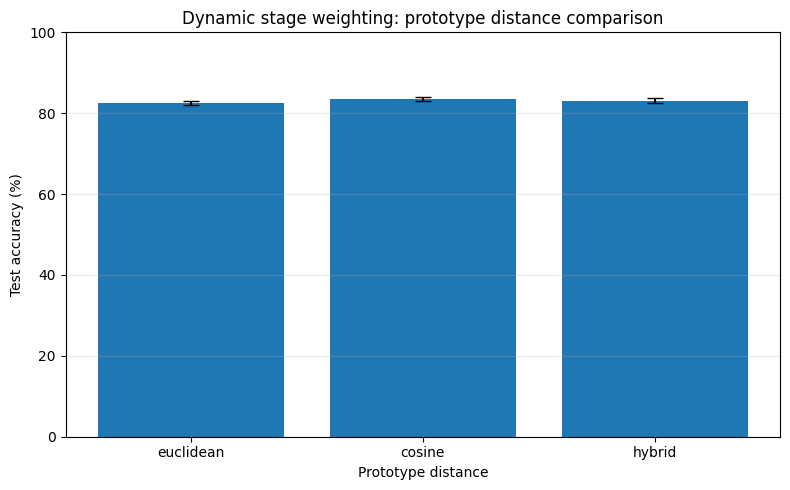

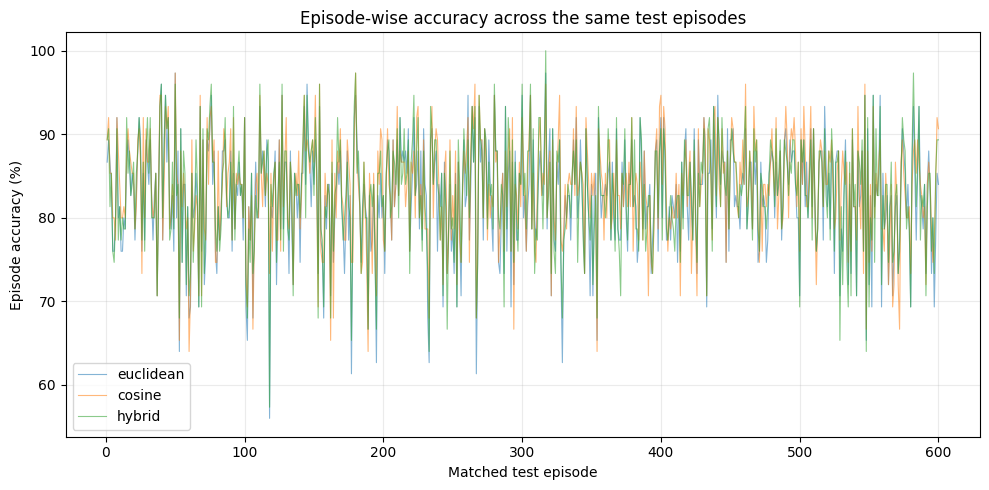

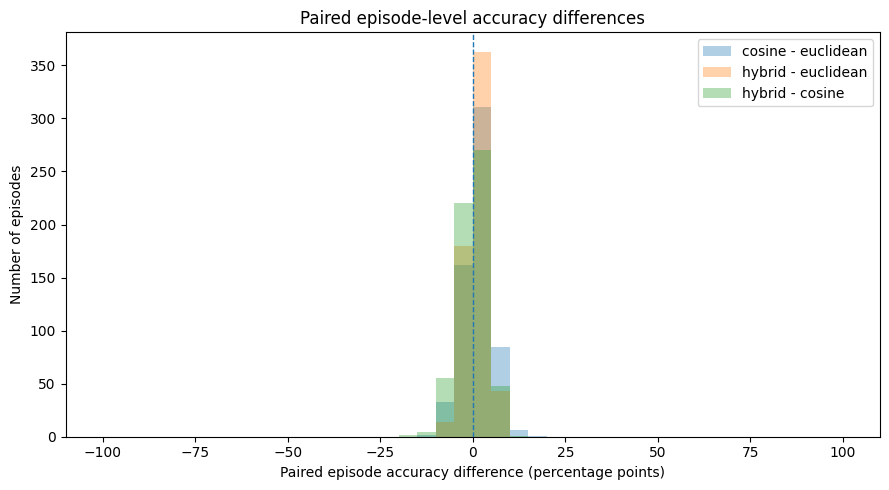

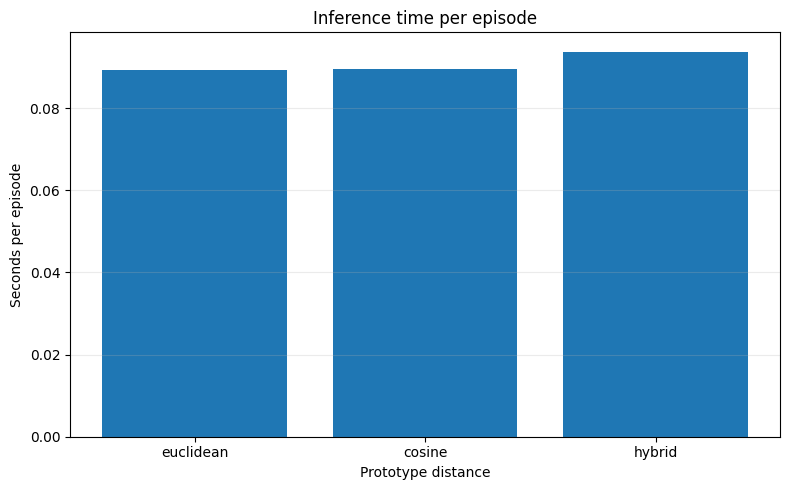

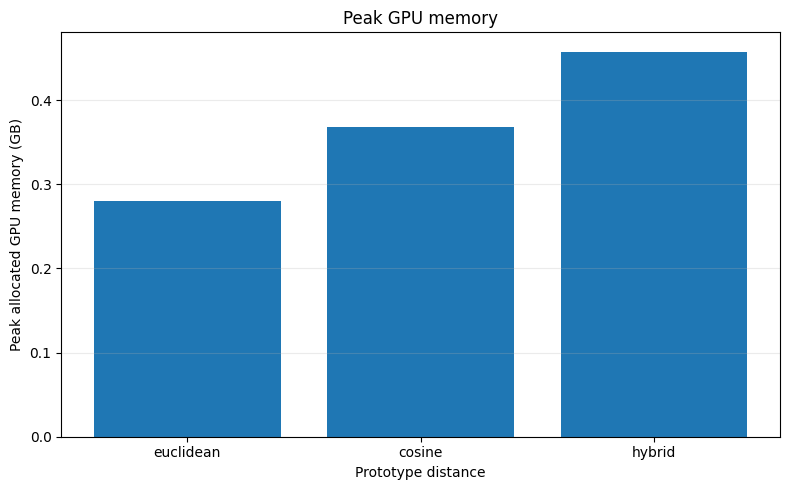

\nDYNAMIC STAGE-WEIGHT SUMMARY


,Distance metric,Stage,Mean dynamic weight,Std across episodes
0,euclidean,maxpool,0.19056,0.00083
1,euclidean,layer1,0.21027,0.00032
2,euclidean,layer2,0.19870,0.00058
3,euclidean,layer3,0.58147,0.01014
4,euclidean,layer4,1.06793,0.01842
5,cosine,maxpool,0.27724,0.00430
6,cosine,layer1,0.28313,0.00049
7,cosine,layer2,0.27449,0.00130
8,cosine,layer3,0.29280,0.00897
9,cosine,layer4,3.45714,0.02134


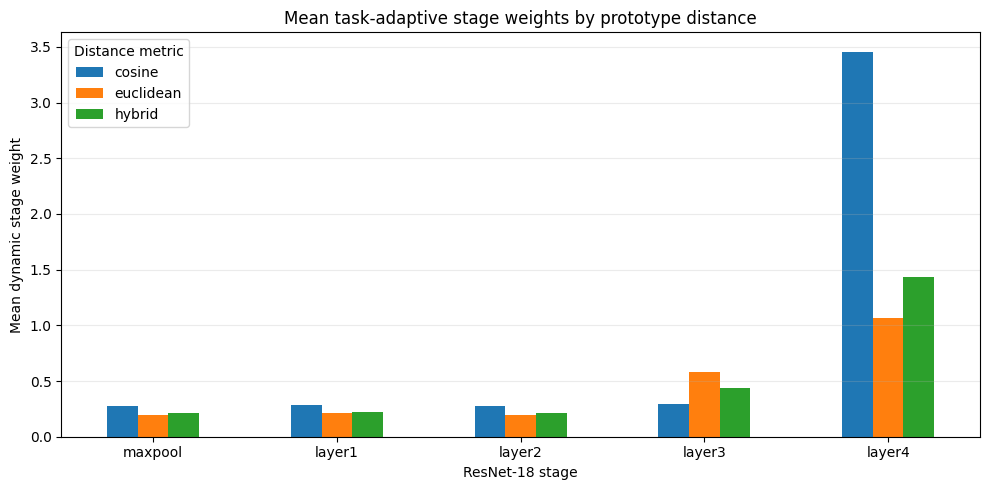

\nAll three variants used dynamic stage weighting and fixed gamma=(0.2, 0.2).
CSV files saved under /kaggle/working/.


In [9]:
# Train and compare the three dynamic-stage-weighting variants.
# All three use the SAME task-adaptive dynamic stage weighting and fixed gamma=(0.2, 0.2).
# Only the prototype distance metric changes.

import copy, gc, math, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

COMPARISON_METRICS = ("euclidean", "cosine", "hybrid")
FIXED_GAMMA = 0.2
TRAIN_SEED = SEED + 100
VAL_SEED = SEED + 200
TEST_SEED = SEED + 300


def reset_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_initial_backbone_state():
    """Load pretrained weights once so every variant starts from the same backbone."""
    if USE_IMAGENET_PRETRAINED:
        try:
            base = resnet18(weights=ResNet18_Weights.DEFAULT)
        except Exception as exc:
            print("Could not load pretrained ResNet-18; using random initialization:", exc)
            base = resnet18(weights=None)
    else:
        base = resnet18(weights=None)
    base.fc = nn.Identity()
    return {k: v.detach().cpu().clone() for k, v in base.state_dict().items()}


# Construct one common initialization for the backbone, attention layers, and dynamic gate.
# Re-seeding before each model construction makes all non-distance parameters identical.
common_backbone_state = make_initial_backbone_state()


def build_variant(metric):
    reset_all_seeds(SEED + 500)
    backbone = resnet18(weights=None)
    backbone.fc = nn.Identity()
    backbone.load_state_dict(common_backbone_state)
    net = PrototypicalNetworks(
        backbone=backbone,
        image_size=IMAGE_SIZE,
        stage_nodes=STAGE_NODES,
        weight=STAGE_WEIGHTS,
        weightlearnable=True,
        gammalearnable=False,       # fixed gamma
        gamma1=FIXED_GAMMA,
        gamma2=FIXED_GAMMA,
        feature_chunk_size=FEATURE_CHUNK_SIZE,
        attention_chunk_size=ATTENTION_CHUNK_SIZE,
        distance_metric=metric,
        cosine_temp=COSINE_TEMP,
        dynamic_weights=True,       # dynamic stage weights in ALL three variants
        dynamic_gate_scale=DYNAMIC_GATE_SCALE,
        fisher_temp=FISHER_TEMP,
    ).to(device)
    return net


def train_variant(metric):
    print("\\n" + "=" * 76)
    print(f"TRAINING: {metric.upper()} prototype distance + dynamic stage weights")
    print("=" * 76)
    reset_all_seeds(TRAIN_SEED)
    net = build_variant(metric)

    # Keep optimizer groups consistent across variants. cosine_temp is retained in
    # all variants; for Euclidean it is unused by the distance calculation.
    backbone_lr = 1e-4
    weights_lr = 0.005
    dynamic_gate_lr = 1e-3
    special = [net.stage_weights, net.gamma1_l, net.gamma2_l, net.cosine_temp]
    dynamic_params = list(net.dynamic_weight_net.parameters())
    excluded_ids = {id(p) for p in special + dynamic_params}
    regular_params = [p for p in net.parameters() if id(p) not in excluded_ids and p.requires_grad]
    groups = [
        {"params": regular_params, "lr": backbone_lr},
        {"params": [net.cosine_temp], "lr": weights_lr},
        {"params": [net.stage_weights], "lr": weights_lr},
        {"params": dynamic_params, "lr": dynamic_gate_lr},
    ]
    optimizer = optim.Adam(groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_EPOCHS, eta_min=1e-6)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and device.type == "cuda")
    trainable_params = [p for p in net.parameters() if p.requires_grad]
    criterion = nn.CrossEntropyLoss()
    best_val = -1.0
    best_state = None
    history = []

    for epoch in range(1, MAX_EPOCHS + 1):
        net.train()
        # Resetting before each epoch aligns sampled training episodes and augmentation
        # randomness across the three distance variants.
        reset_all_seeds(TRAIN_SEED + epoch)
        loss_sum = 0.0
        t0 = time.time()
        pbar = tqdm(train_loader, total=len(train_loader), desc=f"{metric} epoch {epoch}/{MAX_EPOCHS}")
        for support_images, support_labels, query_images, query_labels, _ in pbar:
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast("cuda", enabled=USE_AMP and device.type == "cuda"):
                scores = net(
                    support_images.to(device, non_blocking=True),
                    support_labels.to(device, non_blocking=True),
                    query_images.to(device, non_blocking=True),
                )
                loss = criterion(scores, query_labels.to(device, non_blocking=True))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()
            loss_sum += float(loss.item())
            pbar.set_postfix(loss=f"{loss.item():.4f}")
        if len(train_loader) != N_TRAINING_EPISODES:
            raise RuntimeError(f"Expected {N_TRAINING_EPISODES} training episodes, got {len(train_loader)}")
        scheduler.step()

        # Identical validation episodes each epoch for every metric.
        reset_all_seeds(VAL_SEED)
        val_acc = evaluate(val_loader, net, desc=f"{metric} validation")
        train_loss = loss_sum / len(train_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_accuracy": val_acc})
        print(f"{metric} | epoch {epoch}: train loss={train_loss:.4f}, val accuracy={val_acc:.3f}%, time={(time.time()-t0)/60:.2f} min")
        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}

    if best_state is None:
        raise RuntimeError(f"No best checkpoint produced for {metric}")
    net.load_state_dict(best_state)
    checkpoint_path = os.path.join(SAVE_PATH, f"best_dynamic_{metric}_{SHOT}shot.pth")
    torch.save({
        "model_state_dict": best_state,
        "best_val_accuracy": best_val,
        "distance_metric": metric,
        "dynamic_weights": True,
        "gamma1": FIXED_GAMMA,
        "gamma2": FIXED_GAMMA,
    }, checkpoint_path)
    return net, best_val, history, checkpoint_path


@torch.no_grad()
def evaluate_detailed_matched(net, metric):
    net.eval()
    episode_accs, episode_losses = [], []
    correct_total, query_total = 0, 0
    task_weights = []
    criterion = nn.CrossEntropyLoss(reduction="mean")
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
        torch.cuda.synchronize()
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    reset_all_seeds(TEST_SEED)  # same test episode sequence for each metric
    for support_images, support_labels, query_images, query_labels, _ in tqdm(
        test_loader, total=len(test_loader), desc=f"Testing {metric}", leave=False
    ):
        with torch.amp.autocast("cuda", enabled=USE_AMP and device.type == "cuda"):
            scores = net(
                support_images.to(device, non_blocking=True),
                support_labels.to(device, non_blocking=True),
                query_images.to(device, non_blocking=True),
            )
            labels = query_labels.to(device, non_blocking=True)
            loss = criterion(scores.float(), labels)
        pred = scores.argmax(dim=1)
        n_correct = int((pred == labels).sum().item())
        n_query = int(labels.numel())
        correct_total += n_correct
        query_total += n_query
        episode_accs.append(100.0 * n_correct / n_query)
        episode_losses.append(float(loss.item()))
        if net.last_dynamic_weights is not None:
            task_weights.append(net.last_dynamic_weights.detach().float().cpu().numpy())
    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start
    peak_gb = torch.cuda.max_memory_allocated(device) / (1024 ** 3) if device.type == "cuda" else float("nan")
    n_params = sum(p.numel() for p in net.parameters())
    episode_accs = np.asarray(episode_accs, dtype=float)
    episode_losses = np.asarray(episode_losses, dtype=float)
    if len(episode_accs) != N_TEST_TASKS:
        raise RuntimeError(f"Expected {N_TEST_TASKS} test episodes, got {len(episode_accs)}")
    weights_arr = np.stack(task_weights) if task_weights else None
    return {
        "metric": metric,
        "accuracy": 100.0 * correct_total / query_total,
        "loss": float(episode_losses.mean()),
        "episode_accuracy": episode_accs,
        "episode_loss": episode_losses,
        "inference_seconds": elapsed,
        "seconds_per_episode": elapsed / len(episode_accs),
        "peak_gpu_memory_gb": peak_gb,
        "parameters": n_params,
        "dynamic_weights": weights_arr,
    }


comparison_models = {}
comparison_histories = {}
comparison_rows = []
for metric in COMPARISON_METRICS:
    net, best_val, hist, ckpt = train_variant(metric)
    result = evaluate_detailed_matched(net, metric)
    result["best_val_accuracy"] = best_val
    result["checkpoint"] = ckpt
    comparison_models[metric] = net
    comparison_histories[metric] = hist
    comparison_rows.append(result)
    print(f"\\n{metric.upper()} test accuracy: {result['accuracy']:.4f}% | loss: {result['loss']:.5f} | time/episode: {result['seconds_per_episode']:.5f}s")

# ---------------- Tables ----------------
summary_rows = []
for r in comparison_rows:
    ep = r["episode_accuracy"]
    mean_ep = float(ep.mean())
    sem = float(ep.std(ddof=1) / np.sqrt(len(ep)))
    ci_low, ci_high = mean_ep - 1.96 * sem, mean_ep + 1.96 * sem
    summary_rows.append({
        "Distance metric": r["metric"],
        "Dynamic stage weights": "Yes",
        "Test accuracy (%)": r["accuracy"],
        "95% CI low (%)": ci_low,
        "95% CI high (%)": ci_high,
        "Test loss": r["loss"],
        "Inference time / episode (s)": r["seconds_per_episode"],
        "Total inference (s)": r["inference_seconds"],
        "Peak GPU memory (GB)": r["peak_gpu_memory_gb"],
        "Parameters": r["parameters"],
        "Best validation accuracy (%)": r["best_val_accuracy"],
    })
summary_df = pd.DataFrame(summary_rows)
print("\\nSUMMARY COMPARISON")
display(summary_df.round(5))

paper_df = summary_df[["Distance metric", "Test accuracy (%)", "95% CI low (%)", "95% CI high (%)",
                       "Inference time / episode (s)", "Peak GPU memory (GB)", "Parameters"]].copy()
print("\\nPAPER-STYLE TABLE")
display(paper_df.round(4))

# Paired episode-wise comparisons: the same test episode index is paired across metrics.
paired_rows = []
for i in range(len(comparison_rows)):
    for j in range(i + 1, len(comparison_rows)):
        left, right = comparison_rows[i], comparison_rows[j]
        diff = right["episode_accuracy"] - left["episode_accuracy"]
        wins = int(np.sum(diff > 1e-12))
        ties = int(np.sum(np.abs(diff) <= 1e-12))
        losses = int(np.sum(diff < -1e-12))
        sem = float(diff.std(ddof=1) / np.sqrt(len(diff)))
        paired_rows.append({
            "Comparison": f"{right['metric']} - {left['metric']}",
            "Mean accuracy difference (pp)": float(diff.mean()),
            "95% CI low (pp)": float(diff.mean() - 1.96 * sem),
            "95% CI high (pp)": float(diff.mean() + 1.96 * sem),
            "Std difference (pp)": float(diff.std(ddof=1)),
            "Episodes": len(diff),
            "Wins (%)": 100.0 * wins / len(diff),
            "Ties (%)": 100.0 * ties / len(diff),
            "Losses (%)": 100.0 * losses / len(diff),
        })
paired_df = pd.DataFrame(paired_rows)
print("\\nPAIRED COMPARISONS (episode-level)")
display(paired_df.round(5))

# Save tabular outputs.
summary_df.to_csv("/kaggle/working/dynamic_distance_summary.csv", index=False)
paper_df.to_csv("/kaggle/working/dynamic_distance_paper_table.csv", index=False)
paired_df.to_csv("/kaggle/working/dynamic_distance_paired_comparisons.csv", index=False)

# ---------------- Plots ----------------
metrics = [r["metric"] for r in comparison_rows]
acc_means = [r["episode_accuracy"].mean() for r in comparison_rows]
acc_ci = [1.96 * r["episode_accuracy"].std(ddof=1) / np.sqrt(len(r["episode_accuracy"])) for r in comparison_rows]

plt.figure(figsize=(8, 5))
plt.bar(metrics, acc_means, yerr=acc_ci, capsize=6)
plt.ylabel("Test accuracy (%)")
plt.xlabel("Prototype distance")
plt.title("Dynamic stage weighting: prototype distance comparison")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
for r in comparison_rows:
    plt.plot(np.arange(1, len(r["episode_accuracy"]) + 1), r["episode_accuracy"],
             alpha=0.55, linewidth=0.8, label=r["metric"])
plt.xlabel("Matched test episode")
plt.ylabel("Episode accuracy (%)")
plt.title("Episode-wise accuracy across the same test episodes")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for i in range(len(comparison_rows)):
    for j in range(i + 1, len(comparison_rows)):
        left, right = comparison_rows[i], comparison_rows[j]
        diff = right["episode_accuracy"] - left["episode_accuracy"]
        plt.hist(diff, bins=np.arange(-100, 101, 5), alpha=0.35,
                 label=f"{right['metric']} - {left['metric']}")
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Paired episode accuracy difference (percentage points)")
plt.ylabel("Number of episodes")
plt.title("Paired episode-level accuracy differences")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(metrics, [r["seconds_per_episode"] for r in comparison_rows])
plt.ylabel("Seconds per episode")
plt.xlabel("Prototype distance")
plt.title("Inference time per episode")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

if device.type == "cuda":
    plt.figure(figsize=(8, 5))
    plt.bar(metrics, [r["peak_gpu_memory_gb"] for r in comparison_rows])
    plt.ylabel("Peak allocated GPU memory (GB)")
    plt.xlabel("Prototype distance")
    plt.title("Peak GPU memory")
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

# Dynamic-stage-weight behaviour for each distance metric.
weight_rows = []
for r in comparison_rows:
    w = r["dynamic_weights"]
    if w is not None:
        for stage_i, stage_name in enumerate(STAGE_NODES):
            weight_rows.append({
                "Distance metric": r["metric"],
                "Stage": stage_name,
                "Mean dynamic weight": float(w[:, stage_i].mean()),
                "Std across episodes": float(w[:, stage_i].std()),
            })
weight_df = pd.DataFrame(weight_rows)
print("\\nDYNAMIC STAGE-WEIGHT SUMMARY")
display(weight_df.round(5))
weight_df.to_csv("/kaggle/working/dynamic_stage_weight_summary.csv", index=False)

if not weight_df.empty:
    pivot = weight_df.pivot(index="Stage", columns="Distance metric", values="Mean dynamic weight")
    pivot = pivot.reindex(list(STAGE_NODES))
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_ylabel("Mean dynamic stage weight")
    ax.set_xlabel("ResNet-18 stage")
    ax.set_title("Mean task-adaptive stage weights by prototype distance")
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

print("\\nAll three variants used dynamic stage weighting and fixed gamma=(0.2, 0.2).")
print("CSV files saved under /kaggle/working/.")
